# Position-mix regression: [Defender, Midfielder, Attacker]
Each player gets a target vector that sums to 1, built from the `Pos` column: `DF`→[1,0,0], `MF`→[0,1,0], `FW`→[0,0,1], and multi-position players like `MF,FW` split evenly → [0,.5,.5].

A multi-output **linear regression** predicts the 3 numbers from per-90 playing-style stats. Predictions are clipped at 0 and renormalised to sum to 1.

**Leakage guard:** no position columns (`Pos`, `Pos_stats_*`) are used as features. Goalkeepers are excluded.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
df = pd.read_csv('players_data-2026_2027.csv')
print(df.shape)

(2295, 102)


In [2]:
d = df[df['Pos'].notna() & ~df['Pos'].fillna('').str.contains('GK')].copy()
d = d[d['90s'] >= 3].drop_duplicates(subset=['Player','Squad']).copy()

def pos_vec(p):
    parts = [x.strip() for x in p.split(',')]
    v = np.array([parts.count('DF'), parts.count('MF'), parts.count('FW')], float)
    return v / v.sum()

Y = np.vstack(d['Pos'].map(pos_vec))
Y_df = pd.DataFrame(Y, columns=['DF','MF','FW'], index=d.index)

per90 = ['Sh','SoT','Gls','Ast','Crs','Int','TklW','Fld','Fls','Off','CrdY']
for k in per90: d[k+'_90'] = d[k] / d['90s']
feats = [k+'_90' for k in per90] + ['Age']
X = d[feats].fillna(0)
print(len(d)); Y_df.mean().round(3)

1268


DF    0.362
MF    0.481
FW    0.157
dtype: float64

In [3]:
def to_probs(P):
    P = np.clip(P, 0, None)
    s = P.sum(axis=1, keepdims=True); s[s==0] = 1
    return P / s

Xtr,Xte,Ytr,Yte = train_test_split(X,Y,test_size=0.2,random_state=42)
lr = LinearRegression().fit(Xtr,Ytr)
Pte = to_probs(lr.predict(Xte))
print('Test R2 per class:', [round(r2_score(Yte[:,i],Pte[:,i]),3) for i in range(3)])
print('Test MAE:', round(mean_absolute_error(Yte,Pte),3))
print('Top-class accuracy:', round((Pte.argmax(1)==Yte.argmax(1)).mean(),3))
pd.DataFrame(lr.coef_, index=['DF','MF','FW'], columns=feats).T.round(3)

Test R2 per class: [0.429, 0.232, 0.549]
Test MAE: 0.261
Top-class accuracy: 0.74


,DF,MF,FW
Sh_90,-0.120,0.092,0.028
SoT_90,-0.076,-0.111,0.187
Gls_90,0.015,-0.071,0.056
Ast_90,-0.183,0.121,0.062
Crs_90,-0.030,0.063,-0.033
Int_90,0.094,-0.033,-0.061
TklW_90,-0.025,0.103,-0.078
Fld_90,-0.111,0.077,0.034
Fls_90,-0.144,0.110,0.034
Off_90,-0.056,-0.213,0.269


In [4]:
P = to_probs(cross_val_predict(LinearRegression(), X, Y, cv=KFold(5,shuffle=True,random_state=42)))
pred = pd.DataFrame(P, columns=['p_DF','p_MF','p_FW'], index=d.index)
out = pd.concat([d[['Player','Squad','Pos']], pred], axis=1)
labels = np.array(['DF','MF','FW'])
out['pred_top'] = labels[P.argmax(1)]; out['true_top'] = labels[Y.argmax(1)]
print('5-fold top-class accuracy:', round((out.pred_top==out.true_top).mean(),3))
print(pd.crosstab(out.true_top, out.pred_top))

5-fold top-class accuracy: 0.718
pred_top   DF  FW   MF
true_top              
DF        370   0  135
FW          1  98   32
MF        145  44  443


In [5]:
out['error'] = np.abs(P - Y).sum(axis=1)
print('Most position-ambiguous / misclassified players')
display(out.sort_values('error',ascending=False).head(15).round(2))
print('Sample')
display(out.sample(10, random_state=1).round(2))

Most position-ambiguous / misclassified players


,Player,Squad,Pos,p_DF,p_MF,p_FW,pred_top,true_top,error
1665,Mario Pašalić,Atalanta,MF,0.91,0.04,0.05,DF,MF,1.91
1321,João Mário Lopes,Fiorentina,DF,0.05,0.82,0.13,MF,DF,1.91
2062,Nuno Tavares,Lazio,DF,0.05,0.95,0.00,MF,DF,1.90
155,Ridle Baku,RB Leipzig,DF,0.06,0.74,0.20,MF,DF,1.89
1199,Youssef Lekhedim,Alavés,DF,0.06,0.94,0.00,MF,DF,1.89
1906,Tiago Santos,Lille,DF,0.11,0.64,0.25,MF,DF,1.78
107,Jon Aramburu,Real Sociedad,DF,0.13,0.87,0.00,MF,DF,1.74
1761,Petar Ratkov,Levante,FW,0.47,0.39,0.14,DF,FW,1.72
896,Achraf Hakimi,Paris SG,DF,0.16,0.51,0.32,MF,DF,1.67
307,Kaiki Bruno,Como,DF,0.18,0.61,0.21,MF,DF,1.64


Sample


,Player,Squad,Pos,p_DF,p_MF,p_FW,pred_top,true_top,error
1414,Lewis Miley,Newcastle,"MF,DF",0.71,0.29,0.00,DF,DF,0.41
1041,Thomas Jørgensen,Toulouse,MF,0.27,0.50,0.23,MF,MF,1.00
1007,Ardon Jashari,Milan,MF,0.43,0.31,0.26,DF,MF,1.38
1420,Antoine Mille,Troyes,MF,0.11,0.89,0.00,MF,MF,0.21
603,Désiré Doué,Paris SG,FW,0.00,0.56,0.44,MF,FW,1.11
771,Rubén García,Osasuna,"MF,FW",0.10,0.90,0.00,MF,MF,1.00
110,Cameron Archer,Auxerre,FW,0.12,0.16,0.71,FW,FW,0.57
307,Kaiki Bruno,Como,DF,0.18,0.61,0.21,MF,DF,1.64
117,Arthur,Werder Bremen,"DF,MF",0.58,0.42,0.00,DF,DF,0.16
187,Alessandro Bastoni,Inter,DF,0.61,0.39,0.00,DF,DF,0.77


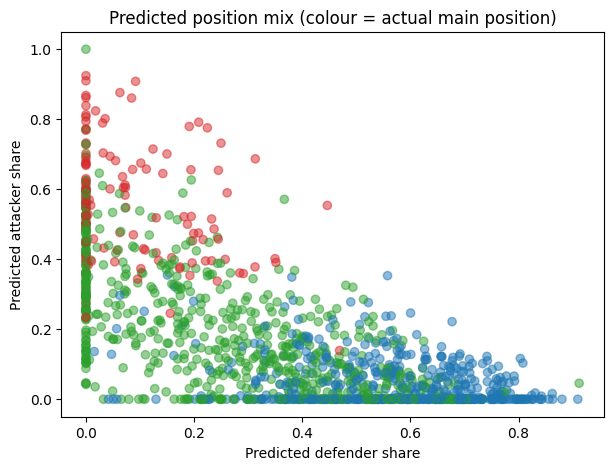

In [6]:
fig,ax = plt.subplots(figsize=(7,5))
cols = {'DF':'tab:blue','MF':'tab:green','FW':'tab:red'}
ax.scatter(P[:,0], P[:,2], c=[cols[t] for t in out.true_top], alpha=.5)
ax.set_xlabel('Predicted defender share'); ax.set_ylabel('Predicted attacker share')
ax.set_title('Predicted position mix (colour = actual main position)'); plt.show()

**Caveats:** linear regression can output values outside 0–1, so predictions are clipped and renormalised afterwards. A multinomial logistic regression would handle this natively. Wingers and wing-backs are the hardest cases, since their per-90 stats overlap with neighbouring roles.